## Схемы Эйлера для ОДУ первого порядка

**Задача Коши:**

$$\begin{matrix}y' = f(x, y)\\y(x_0) = y_0\end{matrix}$$

Сетка: $x_n = x_0 + n h$, $h = \frac{X - x_0}{N}$, $y_n = y(x_n)$.

### 1. Явная схема Эйлера (1-й порядок)

$$
y_{n+1} = y_n + h f(x_n,\ y_n)
$$

### 2. Уточнённая (модифицированная) схема Эйлера (2-й порядок, метод средней точки)

$$
\tilde{y}_{n+1/2} = y_n + \frac{h}{2}\, f(x_n,\ y_n),\\
y_{n+1} = y_n + h f\left( x_n + \frac{h}{2}, \tilde{y}_{n+1/2} \right)
$$

### 3. Схема «полусуммы» (метод Кранка–Николсона / трапеций)

$$
y_{n+1} = y_n + \frac{h}{2}\Big[\, f(x_n,\ y_n) + f(x_{n+1},\ y_{n+1}) \,\Big]
$$



Решаем задачу Коши $y'=f(x,y)$ при $y(0)=y_0$

Пусть $f(x,y)=x\sin{y}$.

Тогда общее решение имеет вид $y(x)=2\arctan{\left(C \exp{\left(\frac{x^2}{2}\right)}\right)}$

$y(0)=y_0 ⇒ C=\tan{\frac{y_0}{2}}$

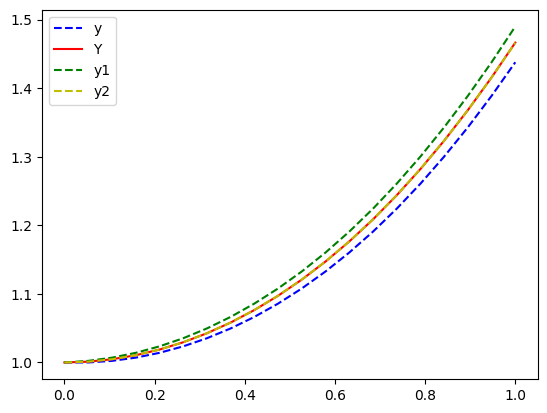

In [16]:
import numpy as np
def f(x, y):
  return x * np.sin(y)

def solve(f, y0=1, X=1, n=100):
  x = np.linspace(0, X, n)
  C = np.tan(y0/2)
  Y = 2 *np.atan(C * np.exp(x**2/2))
  y = np.zeros_like(x)
  y1 = np.zeros_like(x)
  y2 = np.zeros_like(x)
  h = x[1] - x[0]
  y[0] = y0
  y1[0] = y0
  y2[0] = y0
  for i in range(n - 1):
    y[i + 1] = y[i] + h * f(x[i], y[i])
    y1[i + 1] = y1[i] + h * f(x[i+1], y[i+1])
    y2[i + 1] = y2[i] + 0.5 *h * (f(x[i], y[i]) + f(x[i+1], y1[i+1]))

  import matplotlib.pyplot as plt
  ax = plt.subplot()
  ax.plot(x, y, 'b--', label="y")
  ax.plot(x, Y, 'r-', label="Y")
  ax.plot(x, y1, 'g--', label="y1")
  ax.plot(x, y2, 'y--', label="y2")
  ax.legend()
  plt.show()

solve(f, n= 20)


## Решение обыкновенных дифференциальных уравнений

### Задача Коши

Требуется решить дифференциальное уравнение (ДУ) второго порядка, например:

$$
\frac{d^2y}{dy^x}-3\frac{dy}{dx} + 2y = 3x + 1
$$

С начальными условиями ($A$, $B$ - const)

$$y(0) = A, y'(0)=B$$

Для того чтобы решить данное ДУ, нужно составить характеристическое уравнение для однородного уравнения:
- Вместо второй производной записываем $\lambda^2$.
- Вместо первой производной записываем  $\lambda$.
- Вместо функции записываем $1$.

$$\lambda^2 - 3 \lambda + 2 = 0$$
$$(\lambda - 2)(\lambda - 1) = 0$$
$$\lambda_1 = 1 ; \lambda_2 = 2$$

Характеристическое уравнение имеет два различных действительных корня $\lambda_1$ и $\lambda_2$, и общее решение **однородного** уравнения выглядит как

$$y = С_1 \cdot \exp(\lambda_1x) + С_2 \cdot \exp({\lambda_2x}) = С_1 \cdot \exp({x}) + С_2 \cdot \exp({2x})$$

где $С_1$, $С_2$ – константы.


Далее требуется найти какое-либо частное решение $\hat y$  неоднородного уравнения.

Ищем в виде $\hat y=ax+b$

Тогда $\hat y''(x) = 0, \quad \hat y'(x)=a$

То есть

$$-3a + 2(ax + b) = 3x + 1$$

Составим систему (приведем подобные):

$$
\begin{cases}
2a=3 \\
2b-3a=1
\end{cases}
$$

$$
\begin{cases}
a=\frac{3}{2} \\
b=\frac{3a+1}{2}=\frac{11}{4}
\end{cases}
$$

Тогда общее решение уравнения выглядит как

$$y = С_1 \cdot \exp({x}) + С_2 \cdot \exp({2x}) + \frac{3}{2}x + \frac{11}{4}$$

Применяем начальные условия, чтобы найти коэффициенты $С_1$ и $С_2$:

$$
\begin{cases}
y(0) = С_1 + С_2 + \frac{11}{4} = A\\
y'(0) = С_1 + 2С_2 + \frac{3}{2} = B
\end{cases}
$$

$$
\begin{pmatrix}1 & 1 \\1 & 2\end{pmatrix} \cdot
\begin{pmatrix}C_1 \\C_2\end{pmatrix} =
\begin{pmatrix}A-\frac{11}{4} \\B-\frac{3}{2}\end{pmatrix}  
$$

$$
\begin{pmatrix}C_1 \\C_2\end{pmatrix} =
\begin{pmatrix}2 & -1 \\-1 & 1\end{pmatrix} \cdot  
\begin{pmatrix}A-\frac{11}{4} \\B-\frac{3}{2}\end{pmatrix}  
$$

-3.0 1.25


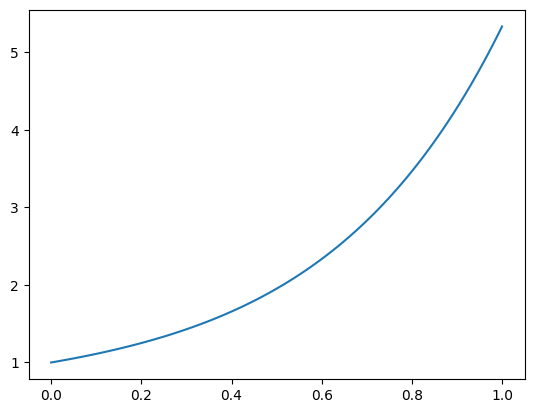

In [1]:
import numpy as np
import matplotlib.pyplot as plt

A, B = 1, 1
C1, C2 = np.array([[2, -1], [-1, 1]]) @ np.array([A - 11/4, B - 3/2])
print(C1, C2)

x = np.linspace(0,1, 100)
y = C1 * np.exp(x) + C2 * np.exp(2 * x) + 1.5 * x + 2.75

ax = plt.subplot()
ax.plot(x, y)


### Метод решения:
Рассмотрим исходное уравнение в виде $$y''=3y'-2y+3x+1$$

Пусть $u_1=y$, а $u_2=y'$ тогда

$$
\begin{cases}
u'_1 = u_2 \\
u'_2=3u_2-2u_1+3x+1
\end{cases}
$$

Если определить вектор $U=(u_1, u_2)$, и функцию $$F(x, U)=\begin{pmatrix}u_2\\3u_2-2u_1+3x+1\end{pmatrix}$$ то систему можно переписать как
$$U'=F(x,U)$$

И решать систему аналогично ОДУ в предыдущем примере

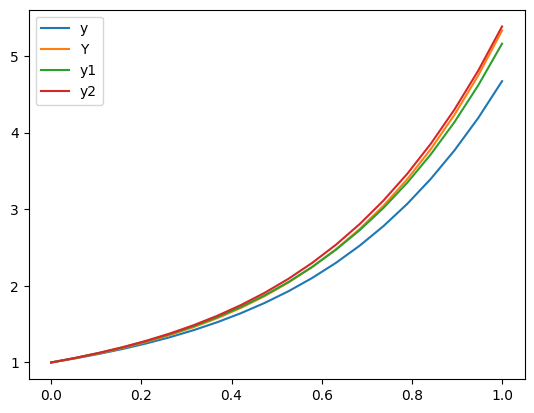

In [10]:
import numpy as np
def F(x, U):
  u1, u2= U
  return np.array([u2, 3 * u2 - 2 * u1 + 3 * x + 1])

def solve(f, A = 1, B = 1, X=1, n=100):
  x = np.linspace(0, X, n)
  h = x[1] - x[0]
  C1, C2 = np.array([[2, -1], [-1, 1]]) @ np.array([A - 11/4, B - 3/2])
  Y = C1 * np.exp(x) + C2 * np.exp(2 * x) + 1.5 * x + 2.75
  U = np.zeros((2, x.shape[0]))
  U1 = np.zeros((2, x.shape[0]))
  U2 = np.zeros((2, x.shape[0]))
  U[0][0] = A; U[1][0] = B
  U1[0][0] = A; U1[1][0] = B
  U2[0][0] = A; U2[1][0] = B

  for i in range(n - 1):
    U[:, i + 1] = U[:, i] + h * f(x[i], U[:, i])
    U1[:, i + 1] = U1[:, i] + h * f(x[i+1], U[:, i+1])
    U2[:, i + 1] = U2[:, i] + 0.5 * h * (f(x[i], U[:, i + 1]) + f(x[i+1], U1[:, i+1]))

  import matplotlib.pyplot as plt
  ax = plt.subplot()
  ax.plot(x, U[0], label="y")
  ax.plot(x, Y, label="Y")
  ax.plot(x, U1[0], label="y1")
  ax.plot(x, U2[0], label="y2")
  ax.legend()
  plt.show()

solve(F, n= 20)


### Задача Дирихле

Требуется решить дифференциальное уравнение (ДУ) второго порядка, например:

$$
\frac{d^2y}{dy^x}-3\frac{dy}{dx} + 2y = 3x + 1
$$

С начальными условиями ($L$, $A$, $B$ - const)

$$y(0) = A, y(L)=B$$

Общее решение уравнения:

$$y = С_1 \cdot \exp({x}) + С_2 \cdot \exp({2x}) + \frac{3}{2}x + \frac{11}{4}$$

Применяем граничные условия, чтобы найти коэффициенты $С_1$ и $С_2$:

$$
\begin{cases}
y(0) = С_1 + С_2 + \frac{11}{4} = A\\
y(L) = С_1 e^L + С_2 e^{2L} +\frac{11}{4}L + \frac{3}{2} = B
\end{cases}
$$

$$
\begin{pmatrix}1 & 1 \\ e^L & e^{2L}\end{pmatrix} \cdot
\begin{pmatrix}C_1 \\C_2\end{pmatrix} =
\begin{pmatrix}A-\frac{11}{4} \\B-\frac{11}{4}L-\frac{3}{2}\end{pmatrix}  
$$

$$
\begin{pmatrix}C_1 \\ C_2 \end{pmatrix} =
{\begin{pmatrix}1 & 1 \\ e^L & e^{2L}\end{pmatrix}}^{-1}
\begin{pmatrix}A-\frac{11}{4} \\B-\frac{11}{4}L-\frac{3}{2}\end{pmatrix}  
$$


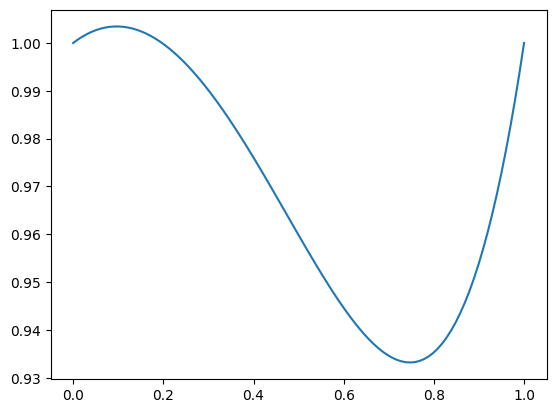

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

A, B = 1, 1
L = 1
C1, C2 = np.linalg.solve(np.array([[1, 1], [np.exp(L), np.exp(2 * L)]]),
                         np.array([A - 11/4, B - 11/4 * L - 3/2]))

x = np.linspace(0,L, 100)
y = C1 * np.exp(x) + C2 * np.exp(2 * x) + 1.5 * x + 2.75

ax = plt.subplot()
ax.plot(x, y)